# Homework 4 — Evaluation Metrics for Classification

Machine Learning Zoomcamp 2026.

[Lessons](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/04-evaluation/README.md) | [Homework requirements](https://github.com/DataTalksClub/machine-learning-zoomcamp/blob/main/cohorts/2026/homework/04-evaluation/homework.md) | [Submission](https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04)

Dataset: https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

SHA-256: 2d9da196bdefd2a45aa0a17ca21c19f06a5d9d56af628be1f04bbb3531cc12e9

Setup prepared by assistant; learning cells are run by Gerhard.

## Environment check
Run this cell first. It checks the interpreter and imports without calculating homework answers.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

print('Python:', sys.version.split()[0])
print('Interpreter:', sys.executable)
print('Working directory:', Path.cwd())
print('NumPy:', np.__version__)
print('Pandas:', pd.__version__)
print('Scikit-learn:', sklearn.__version__)
print('Dataset present:', Path('course_lead_scoring_2026.csv').is_file())

Python: 3.11.17
Interpreter: /opt/conda/envs/ml-zoomcamp/bin/python
Working directory: /workspaces/mlz-04-evaluation-metrics-for-classification
NumPy: 2.4.6
Pandas: 3.0.6
Scikit-learn: 1.9.1
Dataset present: True


## Data inspection

In [2]:
df = pd.read_csv('course_lead_scoring_2026.csv')

print('Shape:', df.shape)
print('\nColumn types:')
print(df.dtypes)
print('\nMissing values:')
print(df.isnull().sum())
print('\nTarget values:')
print(df.converted.value_counts())

Shape: (5000, 9)

Column types:
lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

Target values:
converted
1    2883
0    2117
Name: count, dtype: int64


## Missing-value preparation

In [3]:
categorical = [
    'lead_source',
    'industry',
    'employment_status',
    'location',
]

numerical = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score',
]

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

print('Missing values after preparation:')
print(df.isnull().sum())

Missing values after preparation:
lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64


## Training, validation and test split

In [4]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

print('Full training:', len(df_full_train))
print('Train / validation / test:', len(df_train), len(df_val), len(df_test))
print('Target excluded from training features:', 'converted' not in df_train.columns)

Full training: 4000
Train / validation / test: 3000 1000 1000
Target excluded from training features: True


## Q1 — ROC AUC feature importance

In [5]:
for column in numerical:
    score = df_train[column]
    auc = roc_auc_score(y_train, score)
    inverted = auc < 0.5

    if inverted:
        auc = roc_auc_score(y_train, -score)

    print(f'{column}: AUC={auc:.6f}, inverted={inverted}')

annual_income: AUC=0.608198, inverted=False
number_of_courses_viewed: AUC=0.722989, inverted=False
interaction_count: AUC=0.764920, inverted=False
lead_score: AUC=0.788225, inverted=False


## Q2 — Logistic regression validation AUC

In [6]:
train_dicts = df_train[categorical + numerical].to_dict(orient='records')
val_dicts = df_val[categorical + numerical].to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)

print('Encoded training shape:', X_train.shape)
print(f'Validation AUC: {auc:.6f}')
print(f'Validation AUC rounded: {auc:.3f}')

Encoded training shape: (3000, 28)
Validation AUC: 0.731822
Validation AUC rounded: 0.732


## Q3 — Precision and recall across thresholds

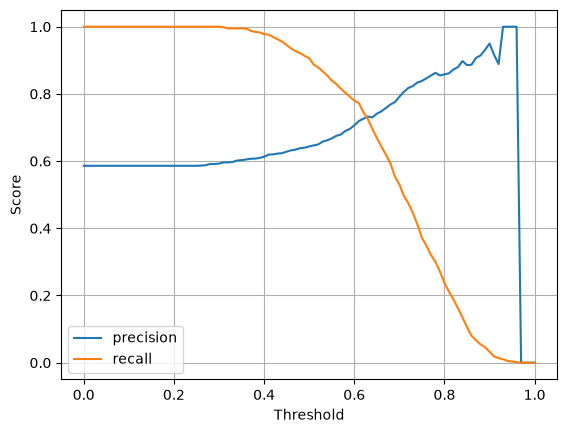

threshold     0.630000
precision     0.732759
recall        0.725256
difference    0.007503
Name: 63, dtype: float64


In [7]:
thresholds = np.linspace(0, 1, 101)
scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0

    scores.append((t, precision, recall))

df_scores = pd.DataFrame(
    scores, columns=['threshold', 'precision', 'recall']
)

plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid()
plt.show()

valid = df_scores[
    (df_scores.precision != 0) | (df_scores.recall != 0)
].copy()
valid['difference'] = abs(valid.precision - valid.recall)

intersection = valid.loc[valid.difference.idxmin()]
print(intersection)

## Q4 — Threshold maximizing F1

In [8]:
p = df_scores.precision
r = df_scores.recall

df_scores['f1'] = (
    2 * p * r / (p + r).replace(0, np.nan)
).fillna(0.0)

best_f1 = df_scores.loc[df_scores.f1.idxmax()]
print(best_f1)

threshold    0.410000
precision    0.619048
recall       0.976109
f1           0.757616
Name: 41, dtype: float64


## Q5 — Five-fold cross-validation

Training and prediction functions; the encoder is fitted separately within each fold.

In [10]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(
        solver='liblinear', C=C, max_iter=1000
    )
    model.fit(X_train, y_train)

    return dv, model


def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [11]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for fold, (train_idx, val_idx) in enumerate(
    kfold.split(df_full_train), start=1
):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold.converted.values
    y_val_fold = df_val_fold.converted.values

    dv_fold, model_fold = train(df_train_fold, y_train_fold, C=1.0)
    y_pred_fold = predict(df_val_fold, dv_fold, model_fold)

    auc = roc_auc_score(y_val_fold, y_pred_fold)
    scores.append(auc)
    print(f'Fold {fold}: AUC={auc:.6f}')

print(f'Mean AUC: {np.mean(scores):.6f}')
print(f'Standard deviation: {np.std(scores):.6f}')
print(f'Standard deviation rounded: {np.std(scores):.3f}')

Fold 1: AUC=0.730560
Fold 2: AUC=0.729573
Fold 3: AUC=0.736343
Fold 4: AUC=0.741245
Fold 5: AUC=0.720914
Mean AUC: 0.731727
Standard deviation: 0.006853
Standard deviation rounded: 0.007


## Q6 — Hyperparameter tuning with five-fold cross-validation

In [12]:
results = []

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]

        y_train_fold = df_train_fold.converted.values
        y_val_fold = df_val_fold.converted.values

        dv_fold, model_fold = train(df_train_fold, y_train_fold, C=C)
        y_pred_fold = predict(df_val_fold, dv_fold, model_fold)

        auc = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(auc)

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)
    results.append((C, mean_auc, std_auc))

    print(
        f'C={C:g}: mean AUC={mean_auc:.6f}, std={std_auc:.6f}'
        f' | rounded: {mean_auc:.3f} ± {std_auc:.3f}'
    )

C=1e-06: mean AUC=0.616734, std=0.018670 | rounded: 0.617 ± 0.019
C=0.001: mean AUC=0.749172, std=0.009996 | rounded: 0.749 ± 0.010
C=1: mean AUC=0.731727, std=0.006853 | rounded: 0.732 ± 0.007


## Answer summary

These results come from Gerhard's executed cells and saved outputs above. No assistant calculation replay was used for this summary.

| Question | Answer | Observed evidence |
| --- | --- | --- |
| Q1 — Numerical feature with highest training AUC | `lead_score` | AUC 0.788225; no inversion needed |
| Q2 — Validation ROC AUC | `0.732` | Raw AUC 0.731822 |
| Q3 — Precision/recall intersection | `0.63` | Precision 0.732759; recall 0.725256; difference 0.007503 |
| Q4 — Threshold maximizing F1 | `0.41` | F1 0.757616 |
| Q5 — Five-fold AUC standard deviation | `0.007` | Raw standard deviation 0.006853; mean AUC 0.731727 |
| Q6 — Best C | `0.001` | Mean AUC 0.749172; standard deviation 0.009996; rounded 0.749 ± 0.010 |

Q6 comparison:

| C | Mean AUC | Standard deviation | Rounded mean ± std |
| --- | --- | --- | --- |
| 0.000001 | 0.616734 | 0.018670 | 0.617 ± 0.019 |
| 0.001 | 0.749172 | 0.009996 | 0.749 ± 0.010 |
| 1 | 0.731727 | 0.006853 | 0.732 ± 0.007 |

The best rounded mean is unique, so no tie-break is needed. The held-out test set was not used for model or threshold selection.
